# 03 - Source-contribution ablation
Question: **how much does each data source help?** We train the same model many times, each time removing one group of features, and see how much the error goes up.

- Same model every time: the Random Forest with the settings chosen in notebook 02.
- Scored with 5-fold time-series cross-validation on train + validation only. **The test set is not used here**, so it stays untouched for the final result.
- Higher MAE after removing a group means that group was useful.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from utils import HISTORY, TARGET, best_forest, load_data, make_pipeline, planning_features, split_by_days

sns.set_theme(style="whitegrid")
df = load_data()
train, val, test = split_by_days(df)
trainval = pd.concat([train, val])
planning = planning_features(df)
len(trainval), len(planning)

(18048, 26)

## 1. Feature groups
`feature_groups.json` puts the route name and the GTFS route facts (number of stops) in one group called `route`. That mixes two different sources, so here we split it:
- **route name**: `bus_route`, `borough` (comes from the MTA ridership data)
- **route facts (GTFS)**: number of stops, longest trip
- **schedule (GTFS)**: scheduled buses per hour, headway, buses per day

In [2]:
groups = json.load(open("../data/feature_groups.json"))
g = {
    "route name": ["bus_route", "borough"],
    "route facts (GTFS)": ["gtfs_n_stops", "gtfs_max_stops_per_trip"],
    "schedule (GTFS)": groups["supply"],
    "weather": groups["weather"],
    "calendar": [c for c in groups["calendar"] if c in planning],
}
covered = sum(g.values(), [])
assert sorted(covered) == sorted(planning)
{k: len(v) for k, v in g.items()}

{'route name': 2,
 'route facts (GTFS)': 2,
 'schedule (GTFS)': 3,
 'weather': 10,
 'calendar': 9}

## 2. Run the experiments
`without(...)` removes whole groups. Each experiment returns 5 MAE values, one per fold.

In [3]:
cv = TimeSeriesSplit(n_splits=5)

def fold_mae(features):
    pipe = make_pipeline(best_forest(), features)
    return -cross_val_score(pipe, trainval[features], trainval[TARGET], cv=cv, scoring="neg_mean_absolute_error")

def without(*names):
    drop = sum((g[n] for n in names), [])
    return [c for c in planning if c not in drop]

experiments = {
    "all planning features": planning,
    "minus route name": without("route name"),
    "minus route facts (GTFS)": without("route facts (GTFS)"),
    "minus schedule (GTFS)": without("schedule (GTFS)"),
    "minus all GTFS (facts + schedule)": without("route facts (GTFS)", "schedule (GTFS)"),
    "minus route name and all GTFS": without("route name", "route facts (GTFS)", "schedule (GTFS)"),
    "minus weather": without("weather"),
    "minus calendar": without("calendar"),
    "history model (all + history features)": planning + HISTORY,
}
folds = {name: fold_mae(features) for name, features in experiments.items()}
print("done")

done


In [4]:
full = folds["all planning features"]
rows = []
for name, mae in folds.items():
    rows.append({
        "experiment": name,
        "MAE": mae.mean(),
        "change vs full": mae.mean() - full.mean(),
        "folds worse than full": int((mae > full).sum()),
    })
ablation = pd.DataFrame(rows)
ablation.round(2)

,experiment,MAE,change vs full,folds worse than full
0,all planning features,69.40,0.00,0
1,minus route name,69.47,0.07,3
2,minus route facts (GTFS),69.38,-0.02,1
3,minus schedule (GTFS),72.44,3.04,4
4,minus all GTFS (facts + schedule),72.44,3.04,4
5,minus route name and all GTFS,135.35,65.95,5
6,minus weather,75.24,5.84,3
7,minus calendar,101.80,32.40,5
8,history model (all + history features),51.87,-17.52,1


**Reading the table** (full planning model: CV MAE 69.4):
- **Calendar is the most important group** (+32 riders when removed, worse in all 5 folds). Hour and weekday carry most of the signal, as the EDA suggested.
- **Route identity is essential, but it can come from two places.** Removing the route name changes nothing (+0.07), because the GTFS route facts and the schedule columns also identify the route (every route has its own number of stops and buses per day). Removing the route name **and** all GTFS columns makes the error double (+66). So the model needs to know which route it is, and it does not matter which source tells it.
- **The GTFS schedule helps a little** (+3.0 when removed, 4 of 5 folds worse, about 4%). The route facts add nothing on top of the route name (-0.02). The schedule has some value because `sched_trips_hr` changes within a route by hour, but hour and route already explain most of that.
- **Weather helps modestly** (+5.8, about 8%) but only 3 of 5 folds got worse, so it is not consistent. Do not read this as 'weather causes ridership': the EDA showed the real weather effect is only about 3-6%. Weather columns can also act as a **season label** (cold means January), which lets the model learn season-level differences. Notebook 04 tests this.
- **History features** lower the error by 17.5 (25%) in this CV. On the final test period the gain was smaller (about 10%), so the benefit varies by period, and in 1 of 5 folds the history model was worse.
- These CV errors (69) are higher than the test error (54) because the early folds train on only a few days of January.

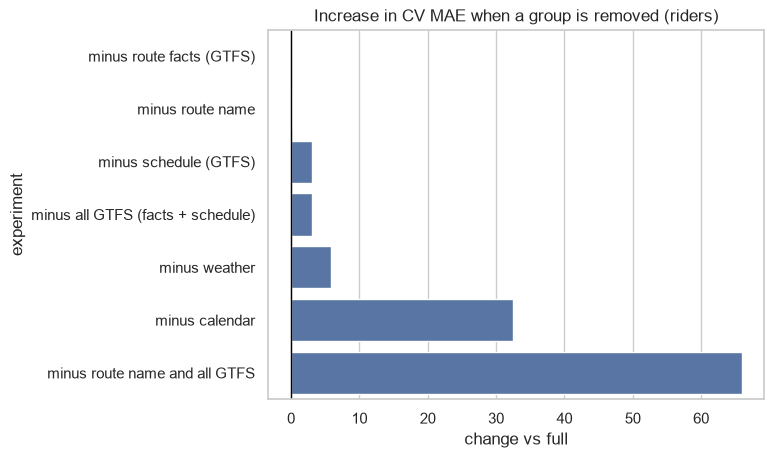

In [5]:
drop_rows = ablation[ablation["experiment"].str.startswith("minus")].sort_values("change vs full")
sns.barplot(data=drop_rows, y="experiment", x="change vs full", color="#4c72b0")
plt.axvline(0, color="black", linewidth=1)
plt.title("Increase in CV MAE when a group is removed (riders)")
plt.savefig("../figures/11_ablation_drop.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Adding sources step by step
Removing a group can hide its value if another group carries the same information (for example, the schedule columns also identify the route). So we also build up from the simplest model and add one source at a time.

In [6]:
steps = [
    ("calendar only", g["calendar"]),
    ("+ route name", g["route name"]),
    ("+ GTFS (route facts + schedule)", g["route facts (GTFS)"] + g["schedule (GTFS)"]),
    ("+ weather", g["weather"]),
]
used, rows, prev = [], [], None
for name, cols in steps:
    used = used + cols
    mae = fold_mae(used)
    rows.append({"step": name, "MAE": mae.mean(), "change from previous step": None if prev is None else mae.mean() - prev})
    prev = mae.mean()
buildup = pd.DataFrame(rows)
buildup.round(2)

,step,MAE,change from previous step
0,calendar only,134.44,NaN
1,+ route name,76.15,-58.29
2,+ GTFS (route facts + schedule),75.14,-1.01
3,+ weather,69.35,-5.79


**Reading the build-up:** with the calendar alone the MAE is 134. Adding the **route name** is by far the biggest step (-58). Adding GTFS then helps only slightly (-1.0), and weather helps a bit more (-5.8). This agrees with the drop-one table: the source that adds most beyond hour/weekday is simply **knowing which route it is**, and the schedule and weather sources add smaller improvements.

**For the report:** MTA ridership + calendar do most of the work. GTFS and weather are useful extras with small effects (a few percent), not major drivers. Presenting this honestly is a stronger result than claiming each source is vital.

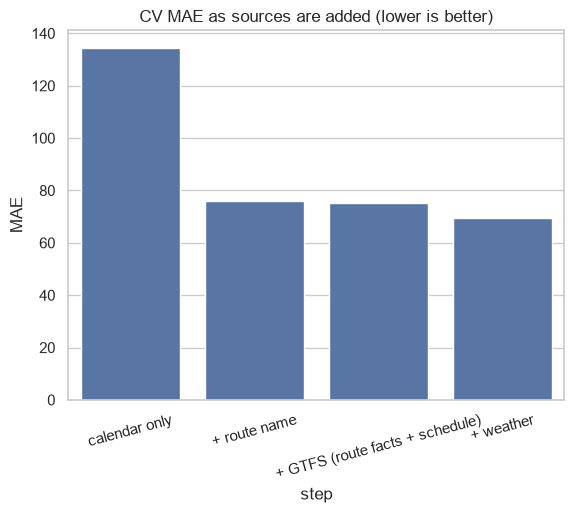

In [7]:
sns.barplot(data=buildup, x="step", y="MAE", color="#4c72b0")
plt.xticks(rotation=15)
plt.title("CV MAE as sources are added (lower is better)")
plt.savefig("../figures/12_ablation_buildup.png", dpi=150, bbox_inches="tight")
plt.show()